# FireWatch AI — Treinamento YOLO12n (dataset local)

Notebook configurado para ler **somente o dataset já existente no computador Windows**:

`C:\Users\<seu_usuario>\Downloads\Fire v3i.yolov11`

**Editor:** VS Code + Jupyter Notebook (`.ipynb`).  
**Dataset:** pasta local `Downloads\Fire v3i.yolov11`.  
**Modelo:** YOLO12n (`yolo12n.pt`).

> **Importante:** esta versão não monta Google Drive nem baixa o dataset. Para acessar os arquivos locais, o notebook precisa executar com um kernel Python local do VS Code. Um runtime remoto do Google Colab não consegue ler diretamente a pasta Downloads do seu computador. Se selecionar o runtime remoto do Colab, será necessário transferir o dataset para ele.


In [3]:
# 1. Identificar o ambiente de execução

from pathlib import Path
import os
import sys
import importlib.util

IN_COLAB = importlib.util.find_spec("google.colab") is not None

if IN_COLAB:
    print("Ambiente detectado: Google Colab")
else:
    print("Ambiente detectado: execução local (por exemplo, kernel do VS Code)")

print("Python:", sys.version)
print("Diretório atual:", Path.cwd())

Ambiente detectado: Google Colab
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Diretório atual: /content


In [4]:
from pathlib import Path

from google.colab import drive

# Montar o Google Drive
drive.mount('/content/drive')

# Caminho do dataset no Google Drive
DATASET_DIR = Path("/content/drive/MyDrive/Fire.v3i.yolov11")

print("Dataset:", DATASET_DIR)
print("Pasta encontrada?", DATASET_DIR.exists())

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Dataset não encontrado: {DATASET_DIR}")

Mounted at /content/drive
Dataset: /content/drive/MyDrive/Fire.v3i.yolov11
Pasta encontrada? True


In [5]:
# 3. Instalar/atualizar as bibliotecas necessárias

%pip install -U ultralytics pyyaml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 66.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [6]:
# 4. Verificar GPU disponível

import torch

print("PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    DEVICE = 0
else:
    print("Nenhuma GPU NVIDIA/CUDA detectada. O treinamento será executado na CPU.")
    DEVICE = "cpu"

# No Google Colab, se CUDA aparecer como False, acesse:
# Ambiente de execução > Alterar tipo de ambiente de execução > T4 GPU.

PyTorch: 2.14.1+cu130
CUDA disponível: True
GPU: NVIDIA A100-SXM4-80GB


In [7]:
# 5. Conferir a estrutura do dataset

required_dirs = [
    DATASET_DIR / "train" / "images",
    DATASET_DIR / "train" / "labels",
    DATASET_DIR / "valid" / "images",
    DATASET_DIR / "valid" / "labels",
    DATASET_DIR / "test" / "images",
    DATASET_DIR / "test" / "labels",
]

for folder in required_dirs:
    print(f"{'OK' if folder.exists() else 'AUSENTE'}: {folder}")

missing = [str(folder) for folder in required_dirs if not folder.exists()]
if missing:
    raise FileNotFoundError(
        "A estrutura esperada não foi encontrada. Verifique se a pasta contém "
        "train, valid e test, cada uma com subpastas images e labels.\\n"
        + "\\n".join(missing)
    )

for split in ["train", "valid", "test"]:
    image_count = len(list((DATASET_DIR / split / "images").glob("*")))
    label_count = len(list((DATASET_DIR / split / "labels").glob("*.txt")))
    print(f"{split}: {image_count} arquivos em images | {label_count} arquivos de anotação")

OK: /content/drive/MyDrive/Fire.v3i.yolov11/train/images
OK: /content/drive/MyDrive/Fire.v3i.yolov11/train/labels
OK: /content/drive/MyDrive/Fire.v3i.yolov11/valid/images
OK: /content/drive/MyDrive/Fire.v3i.yolov11/valid/labels
OK: /content/drive/MyDrive/Fire.v3i.yolov11/test/images
OK: /content/drive/MyDrive/Fire.v3i.yolov11/test/labels
train: 428 arquivos em images | 428 arquivos de anotação
valid: 122 arquivos em images | 122 arquivos de anotação
test: 61 arquivos em images | 61 arquivos de anotação


In [8]:
# 6. Ler o data.yaml e ajustar os caminhos para a estrutura local do dataset

import yaml

original_yaml = DATASET_DIR / "data.yaml"

if not original_yaml.exists():
    raise FileNotFoundError(f"Arquivo data.yaml não encontrado em {DATASET_DIR}")

with open(original_yaml, "r", encoding="utf-8") as file:
    data_config = yaml.safe_load(file)

print("Configuração original:")
print(data_config)

# Sobrescreve os caminhos para evitar problemas com caminhos relativos
# exportados pelo Roboflow.
data_config["path"] = str(DATASET_DIR.resolve())
data_config["train"] = "train/images"
data_config["val"] = "valid/images"
data_config["test"] = "test/images"

# Mantém os nomes e a quantidade de classes definidos pelo dataset.
if "names" not in data_config:
    raise ValueError("O data.yaml não contém a definição das classes em 'names'.")

print("\\nClasses detectadas:", data_config["names"])
print("Quantidade de classes:", data_config.get("nc"))

if isinstance(data_config["names"], dict):
    class_names = list(data_config["names"].values())
else:
    class_names = list(data_config["names"])

if data_config.get("nc") is not None and int(data_config["nc"]) != len(class_names):
    raise ValueError("O valor de 'nc' não corresponde à quantidade de nomes em 'names'.")

# Arquivo de configuração corrigido, salvo na própria pasta do dataset.
FIXED_YAML = DATASET_DIR / "data_firewatch.yaml"

with open(FIXED_YAML, "w", encoding="utf-8") as file:
    yaml.safe_dump(data_config, file, sort_keys=False, allow_unicode=True)

print("\\nArquivo preparado:", FIXED_YAML)
print("Classes do projeto:", class_names)

Configuração original:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['Fire'], 'roboflow': {'workspace': 'vufindr', 'project': 'fire-ztoay', 'version': 3, 'license': 'MIT', 'url': 'https://universe.roboflow.com/vufindr/fire-ztoay/dataset/3'}}
\nClasses detectadas: ['Fire']
Quantidade de classes: 1
\nArquivo preparado: /content/drive/MyDrive/Fire.v3i.yolov11/data_firewatch.yaml
Classes do projeto: ['Fire']


## 7. Treinamento personalizado

O modelo inicial abaixo utiliza pesos pré-treinados (`yolo12n.pt`) e será ajustado com as imagens anotadas do dataset. Isso caracteriza *transfer learning/fine-tuning*, e não treinamento do zero.

Os parâmetros são um ponto de partida. Se ocorrer erro de memória da GPU, reduza `BATCH_SIZE` para 8 ou 4.

In [9]:
from ultralytics import YOLO

MODEL_NAME = "yolo12n.pt"
EPOCHS = 70
IMAGE_SIZE = 640
BATCH_SIZE = 16 if DEVICE != "cpu" else 4

model = YOLO(MODEL_NAME)

train_results = model.train(
    data=str(FIXED_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    patience=20,
    project="runs/firewatch",
    name="yolo12n_fire_smoke",
    exist_ok=True,
    plots=True,
    save=True,
    seed=42
)

print("Treinamento concluído.")
print("Diretório dos resultados:", train_results.save_dir)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Fire.v3i.yolov11/data_firewatch.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=70, erasing=0.4, exist_ok=True, fliplr=0.5, flip

In [10]:
# 8. Localizar os melhores pesos gerados no treinamento

from pathlib import Path

RUN_DIR = Path(train_results.save_dir)
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"

if not BEST_WEIGHTS.exists():
    raise FileNotFoundError(f"Pesos best.pt não encontrados em: {BEST_WEIGHTS}")

print("Melhores pesos:", BEST_WEIGHTS)
print("Arquivo existe:", BEST_WEIGHTS.exists())
print("Últimos pesos:", LAST_WEIGHTS)

Melhores pesos: /content/runs/detect/runs/firewatch/yolo12n_fire_smoke/weights/best.pt
Arquivo existe: True
Últimos pesos: /content/runs/detect/runs/firewatch/yolo12n_fire_smoke/weights/last.pt


In [11]:
# 9. Avaliar o modelo no conjunto de teste

best_model = YOLO(str(BEST_WEIGHTS))

test_metrics = best_model.val(
    data=str(FIXED_YAML),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True,
    project="runs/firewatch",
    name="test_evaluation",
    exist_ok=True
)

print("Avaliação do conjunto de teste concluída.")
print(test_metrics)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
YOLOv12n summary (fused): 160 layers, 2,571,627 parameters, 0 gradients, 7.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.2 ms, read: 0.0±0.0 MB/s, size: 27.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Fire.v3i.yolov11/test/labels.cache... 61 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 61/61 17.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 7.3s/it 29.1s0.5s4
                   all         61         70      0.774      0.914      0.929      0.727
Speed: 1.1ms preprocess, 5.5ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/runs/detect/runs/firewatch/test_evaluation
Avaliação do conjunto de teste concluída.
ultralytics.utils.met

In [12]:
# 10. Testar a detecção em uma imagem do conjunto de teste

test_images_dir = DATASET_DIR / "test" / "images"
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

test_images = [
    p for p in test_images_dir.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
]

if not test_images:
    raise FileNotFoundError("Não encontrei imagens na pasta test/images.")

sample_image = test_images[0]
print("Imagem selecionada:", sample_image)

prediction = best_model.predict(
    source=str(sample_image),
    conf=0.25,
    imgsz=IMAGE_SIZE,
    device=DEVICE,
    save=True,
    project="runs/firewatch",
    name="prediction_example",
    exist_ok=True
)

print("Inferência concluída. Resultado salvo em runs/firewatch/prediction_example.")

Imagem selecionada: /content/drive/MyDrive/Fire.v3i.yolov11/test/images/Datacluster-Fire-and-Smoke-Sample-1-_jpg.rf.cb6a0809739f0e31d7e3e1883edee106.jpg

image 1/1 /content/drive/MyDrive/Fire.v3i.yolov11/test/images/Datacluster-Fire-and-Smoke-Sample-1-_jpg.rf.cb6a0809739f0e31d7e3e1883edee106.jpg: 640x640 1 Fire, 14.3ms
Speed: 1.2ms preprocess, 14.3ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/runs/firewatch/prediction_example
Inferência concluída. Resultado salvo em runs/firewatch/prediction_example.


In [13]:
# 11. Exibir métricas principais

# Os valores abaixo são calculados pelo Ultralytics durante a validação.
print(f"mAP50:     {test_metrics.box.map50:.4f}")
print(f"mAP50-95:  {test_metrics.box.map:.4f}")
print(f"Precision: {test_metrics.box.mp:.4f}")
print(f"Recall:    {test_metrics.box.mr:.4f}")

mAP50:     0.9285
mAP50-95:  0.7274
Precision: 0.7741
Recall:    0.9143


In [14]:
# 12. Copiar os melhores pesos para uma pasta de entrega

import shutil

OUTPUT_DIR = Path("artifacts")
OUTPUT_DIR.mkdir(exist_ok=True)

DELIVERABLE_WEIGHTS = OUTPUT_DIR / "firewatch_yolo12n_best.pt"
shutil.copy2(BEST_WEIGHTS, DELIVERABLE_WEIGHTS)

print("Modelo pronto para integração:", DELIVERABLE_WEIGHTS.resolve())

# Se estiver no Google Colab, oferece o download do arquivo.
if IN_COLAB:
    from google.colab import files
    files.download(str(DELIVERABLE_WEIGHTS))

Modelo pronto para integração: /content/artifacts/firewatch_yolo12n_best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
from pathlib import Path
from IPython.display import display, Image

# Localizar os resultados do treinamento e da avaliação
for folder in [
    Path(train_results.save_dir),
    Path("runs/firewatch/test_evaluation")
]:
    print(f"\nArquivos em: {folder}")

    if folder.exists():
        for file in folder.glob("*.png"):
            print(file)


Arquivos em: /content/runs/detect/runs/firewatch/yolo12n_fire_smoke
/content/runs/detect/runs/firewatch/yolo12n_fire_smoke/confusion_matrix.png
/content/runs/detect/runs/firewatch/yolo12n_fire_smoke/BoxP_curve.png
/content/runs/detect/runs/firewatch/yolo12n_fire_smoke/BoxPR_curve.png
/content/runs/detect/runs/firewatch/yolo12n_fire_smoke/results.png
/content/runs/detect/runs/firewatch/yolo12n_fire_smoke/BoxF1_curve.png
/content/runs/detect/runs/firewatch/yolo12n_fire_smoke/confusion_matrix_normalized.png
/content/runs/detect/runs/firewatch/yolo12n_fire_smoke/BoxR_curve.png

Arquivos em: runs/firewatch/test_evaluation


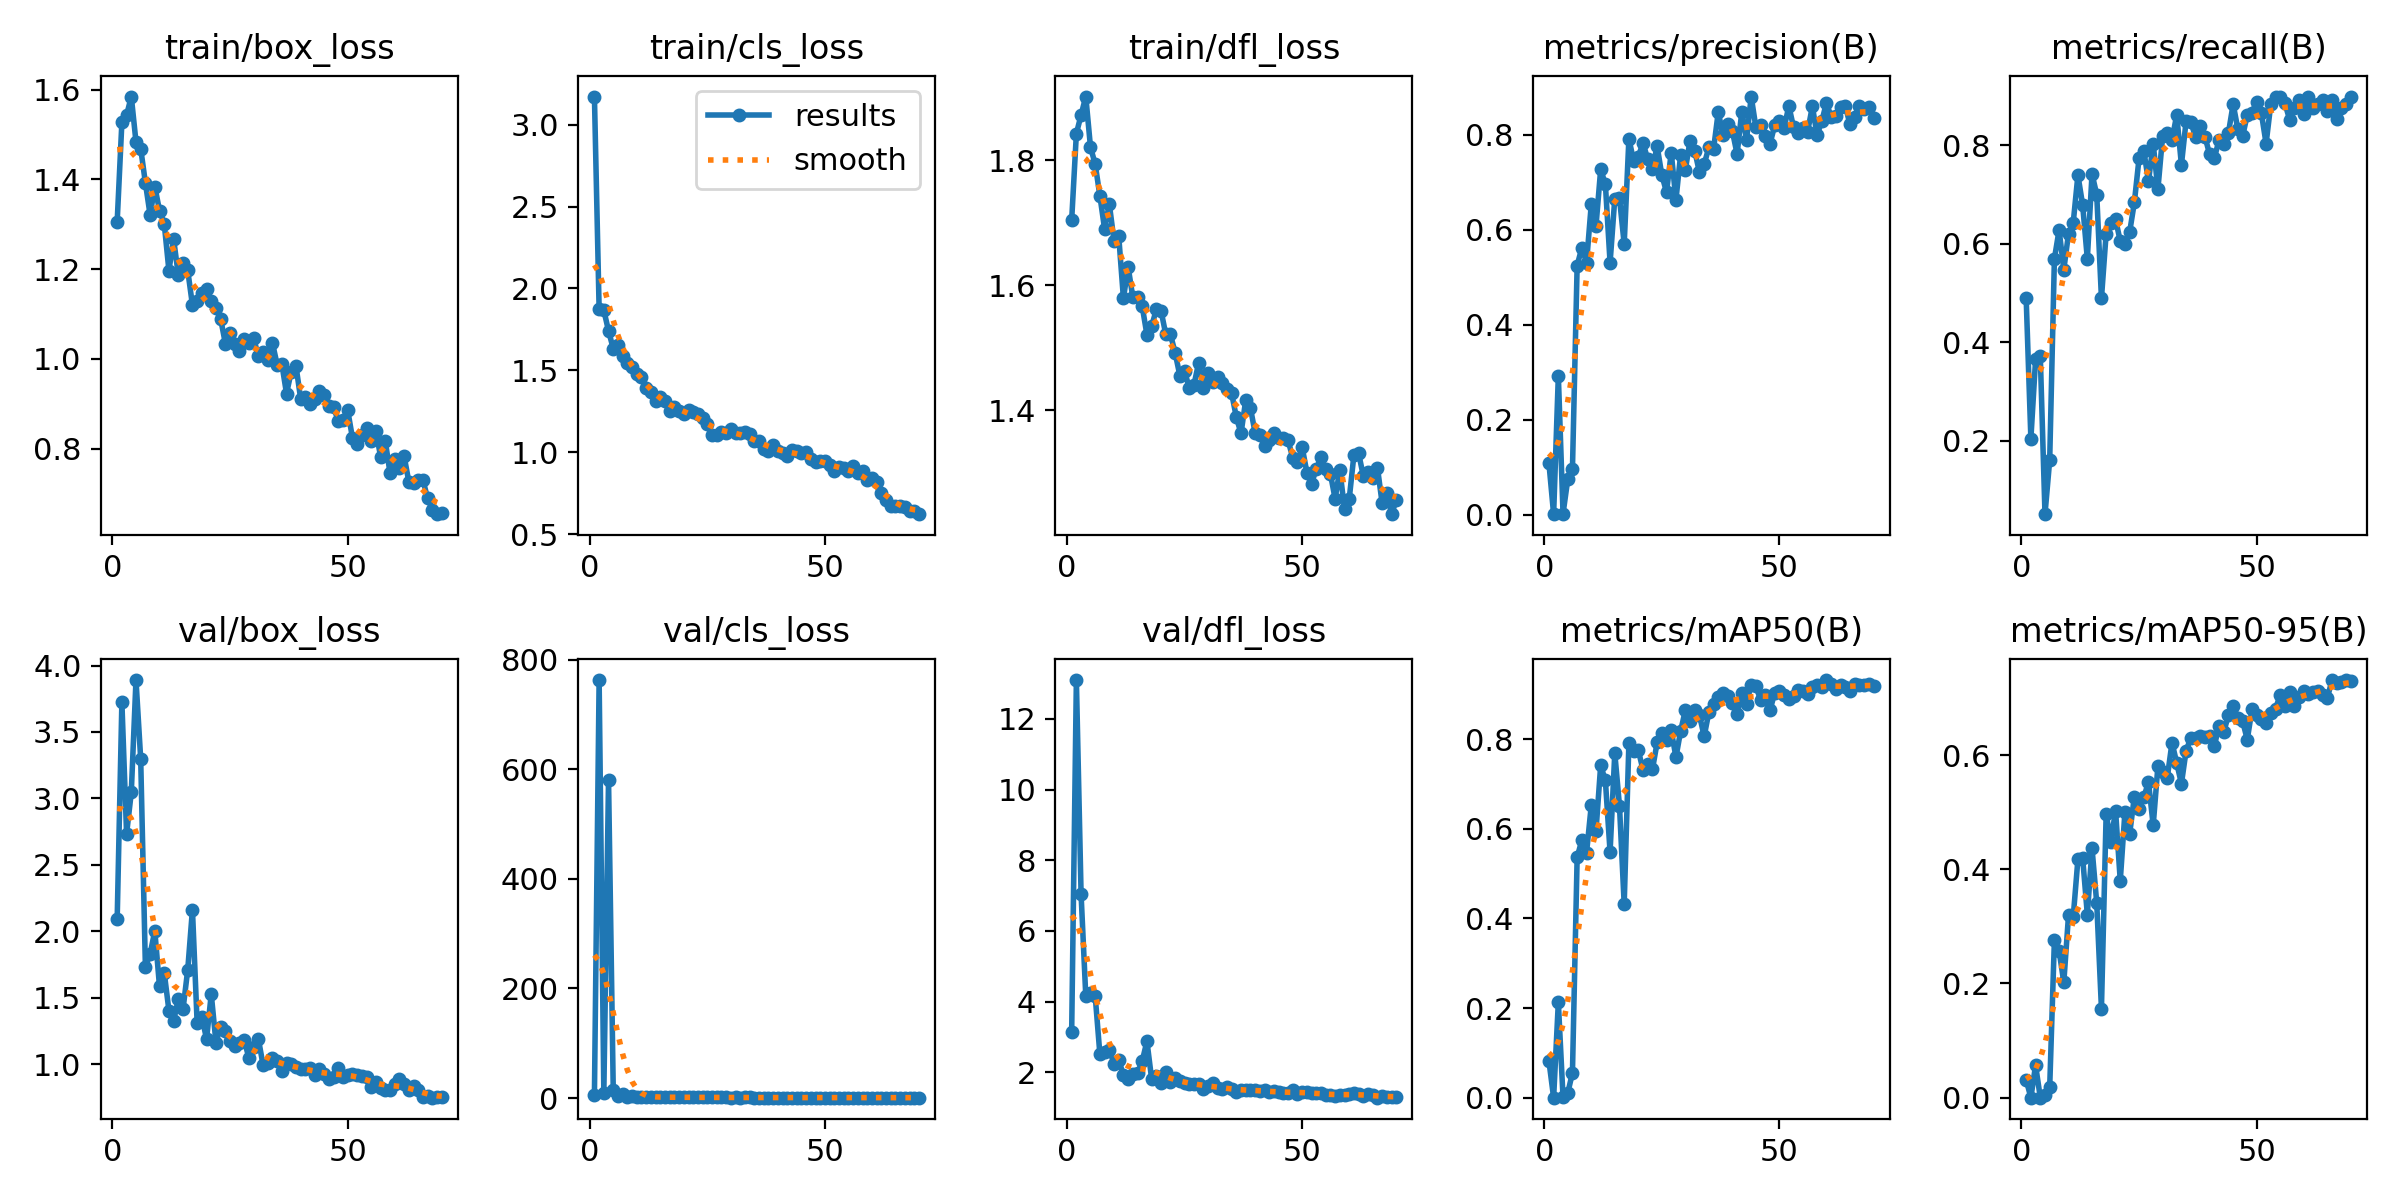

In [16]:
import matplotlib.pyplot as plt
from IPython.display import display, Image

grafico = Path(train_results.save_dir) / "results.png"

if grafico.exists():
    display(Image(filename=str(grafico)))
else:
    print("Gráfico results.png não encontrado.")

In [21]:
from google.colab import drive
from pathlib import Path
import shutil

# Conectar o Google Drive ao runtime
drive.mount('/content/drive')

# Modelo treinado
origem = Path(
    "/content/artifacts/firewatch_yolo12n_best.pt"
)

# Pasta de destino no Google Drive
destino_dir = Path(
    "/content/drive/MyDrive/FireWatchAI/models"
)

destino_dir.mkdir(parents=True, exist_ok=True)

# Copiar modelo
destino = destino_dir / "firewatch_yolo12n_best.pt"

shutil.copy2(origem, destino)

print("Modelo transferido para o Google Drive!")
print("Localização:", destino)
print("Tamanho:", round(destino.stat().st_size / (1024 * 1024), 2), "MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Modelo transferido para o Google Drive!
Localização: /content/drive/MyDrive/FireWatchAI/models/firewatch_yolo12n_best.pt
Tamanho: 5.3 MB
